In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("IMDB-Dataset.csv")
print(df.head())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [3]:
print('Dataset Shape:', df.shape)
print('\nColumn Names:', df.columns.tolist())
print('\nFirst 5 Rows:')
print(df.head())
print('\nMissing Values:')
print(df.isnull().sum())
print('\nNumber of Duplicate Rows:', df.duplicated().sum())
print('\nSentiment Distribution before cleaning:')
print(df['sentiment'].value_counts())

Dataset Shape: (50000, 2)

Column Names: ['review', 'sentiment']

First 5 Rows:
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Missing Values:
review       0
sentiment    0
dtype: int64



Number of Duplicate Rows: 418

Sentiment Distribution before cleaning:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
df['sentiment'] = df['sentiment'].str.capitalize()
df = df.dropna().drop_duplicates().reset_index(drop=True)

print('Cleaned Dataset Shape:', df.shape)
print('\nSentiment Distribution after cleaning:')
print(df['sentiment'].value_counts())

Cleaned Dataset Shape: (49582, 2)

Sentiment Distribution after cleaning:
sentiment
Positive    24884
Negative    24698
Name: count, dtype: int64


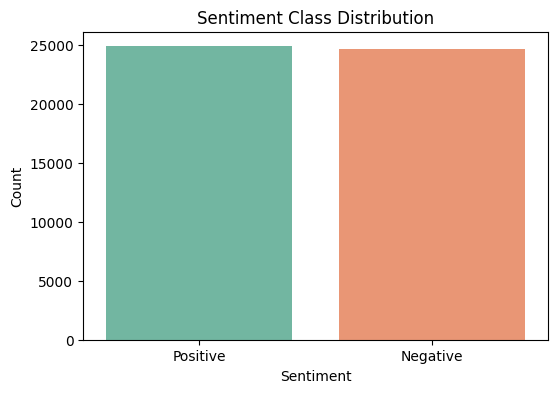

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x='sentiment', data=df, order=['Positive', 'Negative'], hue='sentiment', palette='Set2', legend=False)
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

In [6]:
X = df['review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training set size:', len(X_train))
print('Testing set size:', len(X_test))

Training set size: 39665
Testing set size: 9917


In [7]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), lowercase=True)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print('TF-IDF Training Matrix Shape:', X_train_tfidf.shape)
print('TF-IDF Testing Matrix Shape:', X_test_tfidf.shape)
print('Vocabulary Size:', len(vectorizer.get_feature_names_out()))

TF-IDF Training Matrix Shape: (39665, 5000)
TF-IDF Testing Matrix Shape: (9917, 5000)
Vocabulary Size: 5000


In [8]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)

print('Model training complete.')

Model training complete.


In [9]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {accuracy:.4f}\n')

print('Classification Report:')
print(classification_report(y_test, y_pred))

Test Accuracy: 0.8952

Classification Report:


              precision    recall  f1-score   support

    Negative       0.91      0.88      0.89      4940
    Positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



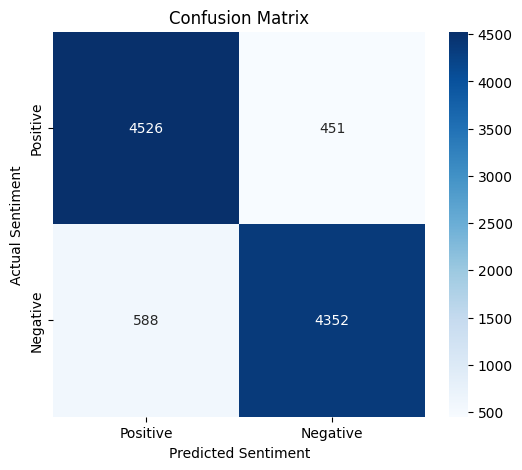

In [10]:
labels = ['Positive', 'Negative']
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

In [11]:
new_reviews = [
    'The product was fantastic, incredible quality and great experience!',
    'Horrible experience, completely broken and a waste of money.',
    'It was okay, had some decent features but nothing special.',
    'Really bad customer service and poor build, very disappointed.',
    'I absolutely loved this purchase, definitely worth buying again!'
]

new_features = vectorizer.transform(new_reviews)
new_predictions = model.predict(new_features)

results_table = pd.DataFrame({
    'Review Text': new_reviews,
    'Predicted Sentiment': new_predictions
})

print(results_table.to_string(index=False))

                                                        Review Text Predicted Sentiment
The product was fantastic, incredible quality and great experience!            Positive
       Horrible experience, completely broken and a waste of money.            Negative
         It was okay, had some decent features but nothing special.            Negative
     Really bad customer service and poor build, very disappointed.            Negative
   I absolutely loved this purchase, definitely worth buying again!            Positive
